# Clasificador de casco y chaleco (301)

Ajuste fino de **MobileNetV3-Small** (pesos de ImageNet) con TensorFlow / Keras sobre recortes de personas de dos datasets públicos con licencia CC BY 4.0: *Construction Safety* (Roboflow 100: casco, chaleco y sus negativos) y *SHEL5K* (personas con y sin casco). Para cada persona da dos probabilidades: `casco` y `chaleco`. Diseño: `docs/specs/301-deteccion-epp/diseno.md` de `supervision-docs` («Entrenamiento» y «Métricas mínimas»).

Antes de correrlo: `descargar_dataset` y `preparar_recortes` (ver `README.md`). El código vive en `clasificador.py` para poder correrlo y probarlo también desde la terminal; este notebook lo usa paso a paso y muestra los resultados. **Si el modelo no alcanza las métricas mínimas, la última celda falla con un mensaje claro** y el modelo no se incluye en la app.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parents[1]  # services/ia (el notebook se ejecuta desde entrenamiento/epp)
sys.path.insert(0, str(RAIZ))

In [2]:
import json

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from entrenamiento.epp import clasificador as c

c.configurar_hilos()
keras.utils.set_random_seed(c.SEMILLA)
print("TensorFlow", tf.__version__, "· Keras", keras.__version__, "· versión del modelo", f"epp-{c.VERSION}")

TensorFlow 2.21.0 · Keras 3.15.1 · versión del modelo epp-1.0.0


## 1. Recortes

Una fila por persona (≥ 64 px de alto, margen de 10 %), con `casco` y `chaleco` (1 = lo lleva) y su peso (0 = no se pudo decidir con las anotaciones). División 70 / 15 / 15 por imagen.

In [3]:
tabla = c.leer_recortes()
resumen = json.loads((c.CARPETA_RECORTES / "resumen.json").read_text(encoding="utf-8"))
entreno, validacion, prueba = (c.cargar_particion(tabla, d) for d in ("entrenamiento", "validacion", "prueba"))
print({d: len(p) for d, p in (("entrenamiento", entreno), ("validacion", validacion), ("prueba", prueba))})
for division, cuentas in resumen["por_division"].items():
    print(division, cuentas)
for fuente, por_division in resumen["por_fuente"].items():
    print(fuente, {d: (n["recortes"], n["sin_casco"], n["sin_chaleco"]) for d, n in por_division.items()})

{'entrenamiento': 12725, 'validacion': 2857, 'prueba': 2808}
entrenamiento {'imagenes': 4344, 'recortes': 12725, 'con_casco': 9904, 'sin_casco': 2737, 'casco_indeterminado': 84, 'con_chaleco': 911, 'sin_chaleco': 644, 'chaleco_indeterminado': 11170}
validacion {'imagenes': 931, 'recortes': 2857, 'con_casco': 2232, 'sin_casco': 606, 'casco_indeterminado': 19, 'con_chaleco': 208, 'sin_chaleco': 118, 'chaleco_indeterminado': 2531}
prueba {'imagenes': 931, 'recortes': 2808, 'con_casco': 2170, 'sin_casco': 606, 'casco_indeterminado': 32, 'con_chaleco': 191, 'sin_chaleco': 106, 'chaleco_indeterminado': 2511}
gsnvb {'entrenamiento': (1827, 88, 644), 'validacion': (418, 20, 118), 'prueba': (369, 10, 106)}
shel5k {'entrenamiento': (10898, 2649, 0), 'validacion': (2439, 586, 0), 'prueba': (2439, 596, 0)}


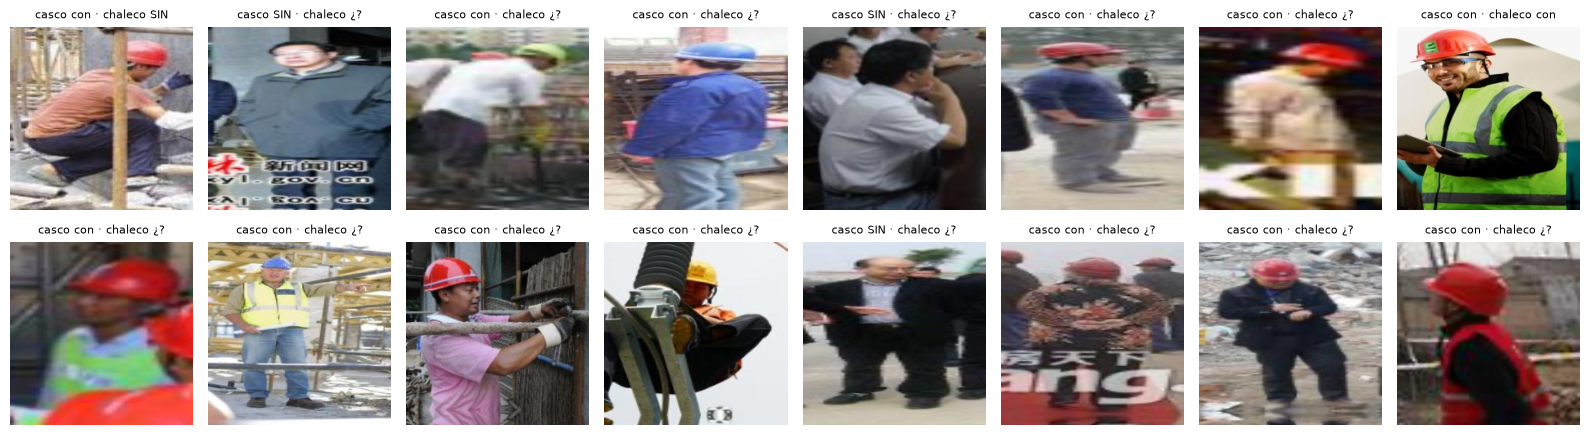

In [4]:
figura, ejes = plt.subplots(2, 8, figsize=(16, 4.6))
muestra = np.random.default_rng(c.SEMILLA).choice(len(entreno), size=16, replace=False)
texto = {(1, 1): "con", (0, 1): "SIN", (0, 0): "¿?", (1, 0): "¿?"}
for eje, i, imagen in zip(ejes.ravel(), muestra, entreno.imagenes(muestra), strict=True):
    eje.imshow(imagen)
    casco = texto[(int(entreno.etiquetas["casco"][i]), int(entreno.pesos["casco"][i]))]
    chaleco = texto[(int(entreno.etiquetas["chaleco"][i]), int(entreno.pesos["chaleco"][i]))]
    eje.set_title(f"casco {casco} · chaleco {chaleco}", fontsize=8)
    eje.axis("off")
figura.tight_layout()
plt.show()

## 2. Modelo

`MobileNetV3Small(include_top=False, weights="imagenet", include_preprocessing=True)` + `GlobalAveragePooling` + `Dropout(0.2)` + dos salidas `Dense(1, sigmoid)`. La entrada es RGB `float32` de 0 a 255: la normalización está dentro del modelo, igual que en el celular.

Pesos de entrenamiento: 0 para lo indeterminado y, para lo decidido, `n / (2 · n_clase)` por atributo, para que las pocas personas «sin casco» pesen tanto como las que lo llevan (decisión técnica).

In [5]:
modelo = c.crear_modelo()
capas_base = len(c.base_del_modelo(modelo).layers)
print(f"Parámetros: {modelo.count_params():,} (base MobileNetV3-Small con {capas_base} capas)")
pesos_entreno = c.pesos_balanceados(entreno)
for a in c.ATRIBUTOS:
    print(a, "pesos por clase:", sorted({round(float(w), 3) for w in pesos_entreno[a]}))
datos_entreno = c.crear_dataset(entreno, pesos_entreno, entrenamiento=True)
datos_validacion = c.crear_dataset(validacion, c.pesos_balanceados(validacion), entrenamiento=False)

Parámetros: 940,274 (base MobileNetV3-Small con 157 capas)
casco pesos por clase: [0.0, 0.638, 2.309]
chaleco pesos por clase: [0.0, 0.853, 1.207]


## 3. Entrenamiento en dos fases

Aumentos (solo en entrenamiento): volteo horizontal, brillo y contraste, rotación ±10° y recorte aleatorio. Fase 1: base congelada, 10 épocas, Adam 1e-3. Fase 2: capas finales de la base descongeladas, con parada temprana por la pérdida de validación (se quedan los mejores pesos).

**Ajuste documentado (01/11/2026):** con la fase 2 del diseño (últimas 30 capas, 10 épocas, Adam 1e-5) el modelo no llegaba a los mínimos; la fase 2 usa las **últimas 60 capas, hasta 20 épocas y Adam 1e-4** (ver `README.md`, «Entrenamiento»).

In [6]:
PLAN = c.Entrenamiento(epocas_fase1=10, tasa_fase1=1e-3, epocas_fase2=20, tasa_fase2=1e-4, capas_descongeladas=60)
plan = c.entrenar(modelo, datos_entreno, datos_validacion, PLAN)
print(f"Entrenamiento: {plan.segundos / 60:.1f} min, {len(plan.historial['loss'])} épocas")
modelo.save(c.CARPETA_SALIDA / "clasificador_epp.keras")

Epoch 1/10


C:\Users\jairo\project-construccion\services\ia\entrenamiento\epp\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


398/398 - 80s - 200ms/step - casco_exactitud: 0.7700 - casco_loss: 0.4768 - chaleco_exactitud: 0.7637 - chaleco_loss: 0.0604 - loss: 0.5373 - val_casco_exactitud: 0.8448 - val_casco_loss: 0.3709 - val_chaleco_exactitud: 0.8595 - val_chaleco_loss: 0.0407 - val_loss: 0.4125


Epoch 2/10


398/398 - 73s - 183ms/step - casco_exactitud: 0.8405 - casco_loss: 0.3670 - chaleco_exactitud: 0.8534 - chaleco_loss: 0.0426 - loss: 0.4097 - val_casco_exactitud: 0.8641 - val_casco_loss: 0.3348 - val_chaleco_exactitud: 0.8895 - val_chaleco_loss: 0.0349 - val_loss: 0.3707


...

Epoch 15/30


398/398 - 110s - 277ms/step - casco_exactitud: 0.9617 - casco_loss: 0.1043 - chaleco_exactitud: 0.9654 - chaleco_loss: 0.0126 - loss: 0.1170 - val_casco_exactitud: 0.9190 - val_casco_loss: 0.2765 - val_chaleco_exactitud: 0.9179 - val_chaleco_loss: 0.0259 - val_loss: 0.3048


Epoch 16/30


398/398 - 112s - 282ms/step - casco_exactitud: 0.9670 - casco_loss: 0.0877 - chaleco_exactitud: 0.9689 - chaleco_loss: 0.0105 - loss: 0.0982 - val_casco_exactitud: 0.9040 - val_casco_loss: 0.2823 - val_chaleco_exactitud: 0.9233 - val_chaleco_loss: 0.0246 - val_loss: 0.3093


Entrenamiento: 23.1 min, 16 épocas


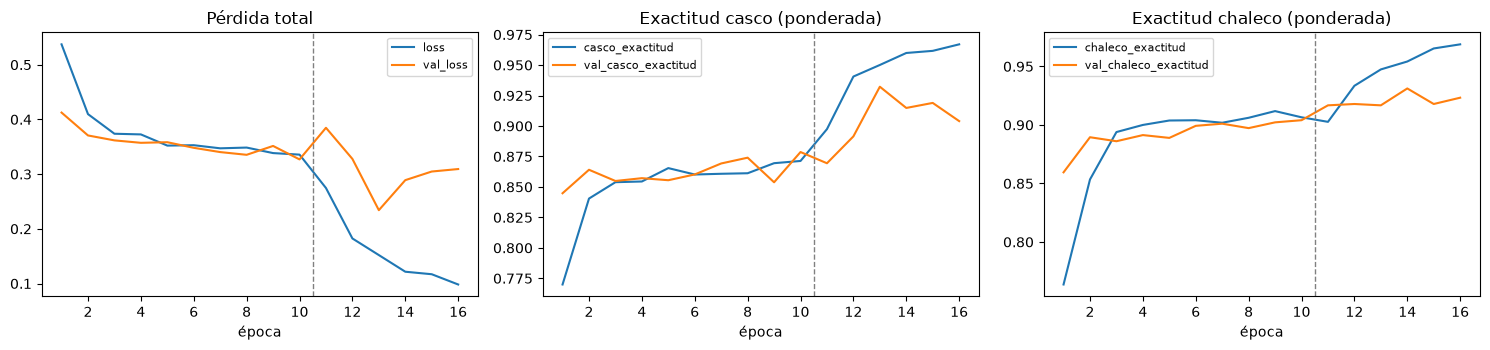

In [7]:
figura, ejes = plt.subplots(1, 3, figsize=(15, 3.6))
h = plan.historial
graficos = [
    ("Pérdida total", ["loss", "val_loss"]),
    ("Exactitud casco (ponderada)", ["casco_exactitud", "val_casco_exactitud"]),
    ("Exactitud chaleco (ponderada)", ["chaleco_exactitud", "val_chaleco_exactitud"]),
]
for eje, (titulo, claves) in zip(ejes, graficos, strict=True):
    for k in claves:
        if k in h:
            eje.plot(range(1, len(h[k]) + 1), h[k], label=k)
    eje.axvline(plan.epocas_fase1 + 0.5, color="gray", linestyle="--", linewidth=1)
    eje.set_title(titulo)
    eje.set_xlabel("época")
    eje.legend(fontsize=8)
figura.tight_layout()
plt.show()

## 4. Umbrales (en validación)

Clase positiva: la **falta** de EPP (`p < umbral` → «sin casco» / «sin chaleco»). El umbral de cada atributo se elige en el 15 % de **validación**, nunca en el de prueba: entre los que dan sensibilidad ≥ 0,85 (se prioriza no dejar pasar a alguien sin casco), el de mayor precisión. Se guardan en `epp.json` para la app.

In [8]:
p_validacion = c.predecir(modelo, validacion)
y_val, w_val = validacion.etiquetas, validacion.pesos
umbrales = {a: c.elegir_umbral(p_validacion[a], y_val[a], w_val[a]) for a in c.ATRIBUTOS}
m_validacion = {a: c.medir(p_validacion[a], y_val[a], w_val[a], umbrales[a]) for a in c.ATRIBUTOS}
for a, m in m_validacion.items():
    print(
        f"{a}: umbral {m.umbral:.2f} · validación: sensibilidad {m.sensibilidad_falta:.3f}, "
        f"precisión {m.precision_falta:.3f}, exactitud {m.exactitud:.3f}, AUC {m.auc:.3f} "
        f"({m.sin_epp} sin / {m.con_epp} con)"
    )

casco: umbral 0.38 · validación: sensibilidad 0.865, precisión 0.924, exactitud 0.956, AUC 0.985 (606 sin / 2232 con)
chaleco: umbral 0.21 · validación: sensibilidad 0.856, precisión 0.935, exactitud 0.926, AUC 0.974 (118 sin / 208 con)


## 5. Evaluación en el 15 % de prueba

| Métrica (clase positiva: falta de EPP) | Mínimo |
|---|---|
| Sensibilidad de «sin casco» y de «sin chaleco» | ≥ 0,85 |
| Precisión de «sin casco» y de «sin chaleco» | ≥ 0,75 |
| Exactitud por atributo | ≥ 0,85 |
| Tamaño de los dos `.tflite` juntos | ≤ 10 MB |

In [9]:
p_prueba = c.predecir(modelo, prueba)
m_prueba = {a: c.medir(p_prueba[a], prueba.etiquetas[a], prueba.pesos[a], umbrales[a]) for a in c.ATRIBUTOS}
print(f"{'atributo':10} {'umbral':>7} {'sens.':>7} {'prec.':>7} {'exact.':>7} {'AUC':>7}  sin/con")
for a, m in m_prueba.items():
    metricas = (m.umbral, m.sensibilidad_falta, m.precision_falta, m.exactitud, m.auc)
    print(f"{a:10}", " ".join(f"{v:7.3f}" for v in metricas), f" {m.sin_epp}/{m.con_epp}")
c.guardar_matriz_confusion(m_prueba, c.CARPETA_SALIDA / "matriz_confusion.png")

atributo    umbral   sens.   prec.  exact.     AUC  sin/con
casco        0.380   0.883   0.926   0.959   0.987  606/2170
chaleco      0.210   0.906   0.950   0.949   0.979  106/191


Las mismas métricas separadas por dataset (con los mismos umbrales). SHEL5K no anota chalecos: solo aporta al casco.

In [10]:
m_fuentes = c.medir_por_fuente(prueba, p_prueba, umbrales)
for fuente, por_atributo in m_fuentes.items():
    for a, m in por_atributo.items():
        metricas = (m.sensibilidad_falta, m.precision_falta, m.exactitud, m.auc)
        print(f"{fuente:7} {a:8}", " ".join(f"{v:7.3f}" for v in metricas), f" {m.sin_epp}/{m.con_epp}")

gsnvb   casco      0.800   1.000   0.994   0.995  10/327
gsnvb   chaleco    0.906   0.950   0.949   0.979  106/191
shel5k  casco      0.884   0.925   0.954   0.985  596/1843


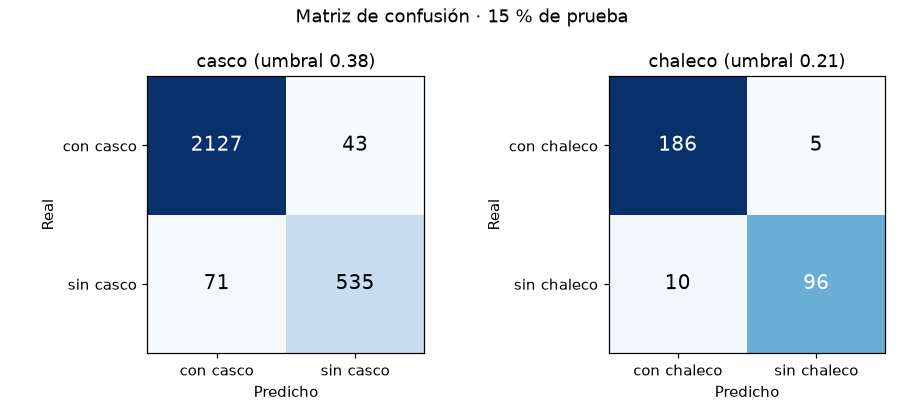

In [11]:
from IPython.display import Image, display

display(Image(filename=str(c.CARPETA_SALIDA / "matriz_confusion.png")))

## 6. Exportación a TensorFlow Lite (float16) y equivalencia

`model.export(salida/saved_model)` y `TFLiteConverter.from_saved_model` con `Optimize.DEFAULT` y `supported_types=[tf.float16]`. El modelo exportado tiene **una sola salida** `(1, 2)` = `[p_casco, p_chaleco]` (orden fijo en `epp.json` → `salidas`). Se comprueba que el `.tflite`, imagen por imagen como en el celular, da lo mismo que Keras en 50 recortes de prueba (diferencia máxima 0,02).

In [12]:
ruta_tflite = c.exportar_tflite(modelo)
diferencia = c.comprobar_equivalencia(modelo, ruta_tflite, prueba.imagenes(range(c.RECORTES_EQUIVALENCIA)))
tamanos = {"clasificador_epp.tflite": c.tamano_mb(ruta_tflite)}
detector = c.CARPETA_EPP / "datos" / "efficientdet_lite0.tflite"  # se descarga de MediaPipe (ver README)
if detector.exists():
    tamanos["efficientdet_lite0.tflite"] = c.tamano_mb(detector)
print(f"Diferencia máxima Keras/TFLite en {c.RECORTES_EQUIVALENCIA} recortes: {diferencia:.5f}")
print({k: f"{v:.2f} MB" for k, v in tamanos.items()}, f"juntos: {sum(tamanos.values()):.2f} MB")

INFO:tensorflow:Assets written to: C:\Users\jairo\project-construccion\services\ia\entrenamiento\epp\salida\saved_model\assets


INFO:tensorflow:Assets written to: C:\Users\jairo\project-construccion\services\ia\entrenamiento\epp\salida\saved_model\assets


Diferencia máxima Keras/TFLite en 50 recortes: 0.00997
{'clasificador_epp.tflite': '1.87 MB', 'efficientdet_lite0.tflite': '4.39 MB'} juntos: 6.25 MB


C:\Users\jairo\project-construccion\services\ia\entrenamiento\epp\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 7. Archivos para la app y verificación de las métricas mínimas

`epp.json` (versión, umbrales, tamaño de entrada y orden de las salidas) y `metricas.json` (prueba y validación, tamaños, equivalencia y si cumple). Las métricas se guardan siempre, cumplan o no; la última línea falla si no se alcanzan los mínimos.

In [13]:
c.guardar_configuracion_app(umbrales)
c.guardar_metricas(
    m_prueba,
    m_validacion,
    plan=plan,
    resumen_recortes=resumen,
    tamanos_mb=tamanos,
    diferencia_tflite=diferencia,
    prueba_por_fuente=m_fuentes,
)
print((c.CARPETA_SALIDA / "epp.json").read_text(encoding="utf-8"))
c.verificar_minimos(m_prueba, sum(tamanos.values()) if len(tamanos) == 2 else None)
print("El modelo cumple las métricas mínimas del diseño.")

{
  "version": "1.0.0",
  "versionModelo": "epp-1.0.0",
  "entrada": {
    "alto": 224,
    "ancho": 224,
    "canales": 3,
    "tipo": "float32",
    "rango": [
      0,
      255
    ]
  },
  "salidas": [
    "casco",
    "chaleco"
  ],
  "umbrales": {
    "casco": 0.38,
    "chaleco": 0.21
  }
}

El modelo cumple las métricas mínimas del diseño.
